# Tests of pseudorandom number generators

*Beyond the exercises — chapter 4 of the scriptum.*

---

In the notebook `ch04_generators` we saw that RANDU has a flaw which a two-dimensional picture does
not show. Here we acquire the tools that look for such flaws **systematically**, and we turn them
loose on three generators: a good one, a suspect one and a downright bad one.

- how a statistical test works at all, and what it means for a generator to have "passed"
- the **χ² test** as the common foundation
- the **frequency** test (uniformity), the **serial** test (pairs and triples), the **poker** test,
  the **runs** test, the **autocorrelation** test
- and above all: **which test catches what** — each one sees a different flaw

This is the lower bound. For serious work there are batteries such as TestU01 or Dieharder, which
contain hundreds of tests.

In [1]:
import math
import random
from itertools import product

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def _gamma_P(a, x):
    '''The regularized lower incomplete gamma function P(a, x). A series for small x, a continued fraction for large.'''
    if x <= 0:
        return 0.0
    if x < a + 1.0:                       # the series expansion
        ap, total, term = a, 1.0 / a, 1.0 / a
        for _ in range(500):
            ap += 1.0
            term *= x / ap
            total += term
            if abs(term) < abs(total) * 1e-15:
                break
        return total * math.exp(-x + a * math.log(x) - math.lgamma(a))
    # the continued fraction for Q(a, x) = 1 - P(a, x)
    tiny = 1e-300
    b, c, d = x + 1.0 - a, 1.0 / tiny, 1.0 / (x + 1.0 - a)
    h = d
    for i in range(1, 500):
        an = -i * (i - a)
        b += 2.0
        d = an * d + b
        if abs(d) < tiny:
            d = tiny
        c = b + an / c
        if abs(c) < tiny:
            c = tiny
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < 1e-15:
            break
    return 1.0 - math.exp(-x + a * math.log(x) - math.lgamma(a)) * h


def chi2_p(stat, df):
    '''The p-value of the χ² test: P(χ²_df > stat).'''
    return 1.0 - _gamma_P(df / 2.0, stat / 2.0)


def normal_p(z):
    '''The two-sided p-value for a standardized statistic z.'''
    return math.erfc(abs(z) / math.sqrt(2))


# a check against tabulated critical values (p = 0.05)
for df, crit in ((1, 3.8415), (2, 5.9915), (5, 11.0705), (10, 18.3070), (50, 67.5048)):
    p = chi2_p(crit, df)
    assert abs(p - 0.05) < 1e-3, (df, p)
    print(f"χ² df = {df:>2}: critical value {crit:8.4f} -> p = {p:.4f}")
print("the χ² implementation agrees with the table")

χ² df =  1: critical value   3.8415 -> p = 0.0500
χ² df =  2: critical value   5.9915 -> p = 0.0500
χ² df =  5: critical value  11.0705 -> p = 0.0500
χ² df = 10: critical value  18.3070 -> p = 0.0500
χ² df = 50: critical value  67.5048 -> p = 0.0500
the χ² implementation agrees with the table


## 1. How a generator is tested

A test always has the same skeleton:

1. **The null hypothesis $H_0$:** the numbers are independent and uniform on $[0,1)$.
2. **The statistic:** a number computed from the sequence, whose distribution under $H_0$ we know.
3. **The p-value:** the probability that, under $H_0$, the statistic would come out at least as
   extreme as the one measured.
4. **The decision:** a small p-value (below $0.01$, say) means the data do not fit $H_0$.

Two things that are easy to misunderstand:

- **"It passed the test" does not mean "it is good."** It only means that *this* test does not see
  this flaw. RANDU passes the frequency test without flinching.
- **A very small p-value is not the only way to fail.** A p-value too close to one is suspicious as
  well — the data fit the theory *better* than chance would allow. That is how faked results are
  recognized.

Done properly, a test is run many times on different stretches, and the p-values themselves should
come out uniform on $[0,1)$. That is called a second-order test and we do it at the end of the
notebook.

## 2. The χ² test as the common foundation

Most of the tests below have the same form: we split the outcomes into $k$ classes, compare the
observed counts $O_i$ with the expected ones $E_i$ and compute

$$\chi^2 = \sum_{i=1}^{k}\frac{(O_i - E_i)^2}{E_i}.$$

Under $H_0$, $\chi^2$ has approximately the distribution with $k - 1$ degrees of freedom (minus one
more degree for every parameter estimated from the data). The approximation is usable when every
$E_i$ is at least roughly 5.

In [2]:
def chi2_test(observed, expected, df=None):
    '''The χ² statistic and the p-value for two lists of the same length.'''
    stat = sum((o - e) ** 2 / e for o, e in zip(observed, expected))
    if df is None:
        df = len(observed) - 1
    return stat, chi2_p(stat, df)


# --- the generators we are going to try ---

def mt(n):
    '''The Mersenne Twister (Python's random).'''
    return [random.random() for _ in range(n)]


def randu(n, seed=1):
    '''RANDU: x <- 65539 x mod 2^31.'''
    m, x, out = 2**31, seed, []
    for _ in range(n):
        x = (65539 * x) % m
        out.append(x / m)
    return out


def lcg_small(n, seed=1):
    '''A downright bad LCG: modulus 2048, so only 2048 distinct values.'''
    m, x, out = 2048, seed, []
    for _ in range(n):
        x = (1229 * x + 1) % m
        out.append(x / m)
    return out


GENERATORS = (("Mersenne Twister", mt), ("RANDU", randu), ("small LCG (m = 2048)", lcg_small))
N = 200_000
SAMPLES = {name: f(N) for name, f in GENERATORS}
print(f"prepared {format(N, ',').replace(',', ' ')} numbers from each generator")

prepared 200 000 numbers from each generator


## 3. The frequency test

The simplest one possible: we split $[0,1)$ into $k$ equal bins and look at whether roughly $n/k$
numbers fell into each.

This test catches only gross non-uniformity. The sequence $0, \tfrac1k, \tfrac2k, \dots$ repeated over
and over passes it with flying colours, even though it is perfectly predictable.

In [3]:
def frequency_test(xs, k=100):
    counts = [0] * k
    for x in xs:
        counts[min(int(x * k), k - 1)] += 1
    return chi2_test(counts, [len(xs) / k] * k)


print(f"{'generator':22s} {'χ²':>10s} {'p':>10s}   verdict")
for name, _ in GENERATORS:
    stat, p = frequency_test(SAMPLES[name])
    print(f"{name:22s} {stat:10.1f} {p:10.4f}   {'passed' if p > 0.01 else 'FAILED'}")

generator                      χ²          p   verdict
Mersenne Twister            118.5     0.0885   passed
RANDU                        89.8     0.7345   passed
small LCG (m = 2048)        118.8     0.0853   passed


## 4. The serial test: pairs and triples

Uniformity of the individual numbers is not enough — what we want is **independence**. The serial test
takes consecutive $d$-tuples as a point in a $d$-dimensional cube, splits the cube into $k^d$ cells
and applies χ² again.

For $d = 2$ this is exactly the picture of pairs from the generators notebook, except measured instead
of eyeballed. And for $d = 3$ it is the trap RANDU falls into.

In [4]:
def serial_test(xs, d=2, k=10):
    '''The d-dimensional serial test on non-overlapping d-tuples.'''
    counts = {}
    m = len(xs) // d
    for i in range(m):
        cell_ = tuple(min(int(xs[i * d + j] * k), k - 1) for j in range(d))
        counts[cell_] = counts.get(cell_, 0) + 1
    all_cells = list(product(range(k), repeat=d))
    observed = [counts.get(b, 0) for b in all_cells]
    return chi2_test(observed, [m / k**d] * len(all_cells))


print(f"{'generator':22s} {'d=2, χ²':>12s} {'p':>9s}   {'d=3, χ²':>12s} {'p':>9s}")
for name, _ in GENERATORS:
    s2, p2 = serial_test(SAMPLES[name], d=2, k=12)
    s3, p3 = serial_test(SAMPLES[name], d=3, k=8)
    print(f"{name:22s} {s2:12.1f} {p2:9.4f}   {s3:12.1f} {p3:9.4f}")

generator                   d=2, χ²         p        d=3, χ²         p
Mersenne Twister              147.7    0.3757          476.7    0.8592


RANDU                         143.2    0.4804          693.7    0.0000


small LCG (m = 2048)       138296.8    0.0000       101824.0    0.0000


This is the heart of the whole notebook. **RANDU passes the two-dimensional test and fails the
three-dimensional one** — exactly as the structure of 15 planes promised. Had we tested only up to two
dimensions, we would have found nothing, and that is precisely what happened for years.

Notice the small LCG as well: it **passed the frequency test**. It has only 2048 distinct values, but
those are spread evenly over $[0,1)$, so they divide among a hundred bins exactly as they should. Only
the pairs give it away — 2048 possible states cannot fill 144 cells independently.

## 5. The poker test

We take the numbers in groups of five, turn each into a digit $\lfloor 10\gamma \rfloor$, and classify
the quintuple as a poker hand according to how many digits repeat. The probabilities can be computed
exactly:

| Hand | Probability |
|---|---|
| all five different | $0.3024$ |
| one pair | $0.5040$ |
| two pairs | $0.1080$ |
| three of a kind | $0.0720$ |
| full house | $0.0090$ |
| four of a kind | $0.0045$ |
| five of a kind | $0.0001$ |

The test is sensitive to repetition, which the frequency test does not see.

In [5]:
PATTERNS = {
    (1, 1, 1, 1, 1): ("all five different", 0.3024),
    (1, 1, 1, 2):    ("one pair",           0.5040),
    (1, 2, 2):       ("two pairs",          0.1080),
    (1, 1, 3):       ("three of a kind",    0.0720),
    (2, 3):          ("full house",         0.0090),
    (1, 4):          ("four of a kind",     0.0045),
    (5,):            ("five of a kind",     0.0001),
}
ORDER = list(PATTERNS)


def poker_test(xs):
    counts = {v: 0 for v in ORDER}
    m = len(xs) // 5
    for i in range(m):
        digits = [min(int(xs[5 * i + j] * 10), 9) for j in range(5)]
        freqs = {}
        for c in digits:
            freqs[c] = freqs.get(c, 0) + 1
        counts[tuple(sorted(freqs.values()))] += 1
    observed = [counts[v] for v in ORDER]
    expected = [m * PATTERNS[v][1] for v in ORDER]
    return chi2_test(observed, expected), counts, m


print(f"{'generator':22s} {'χ²':>12s} {'p':>10s}")
for name, _ in GENERATORS:
    (stat, p), counts, m = poker_test(SAMPLES[name])
    print(f"{name:22s} {stat:12.1f} {p:10.4f}")

(_, _), counts, m = poker_test(SAMPLES["Mersenne Twister"])
print(f"\nthe breakdown for the Mersenne Twister ({m} quintuples):")
print(f"  {'hand':20s} {'observed':>11s} {'expected':>10s}")
for v in ORDER:
    print(f"  {PATTERNS[v][0]:20s} {counts[v]:11d} {m * PATTERNS[v][1]:10.0f}")

generator                        χ²          p
Mersenne Twister                6.4     0.3813
RANDU                           2.3     0.8908


small LCG (m = 2048)         1011.1     0.0000



the breakdown for the Mersenne Twister (40000 quintuples):
  hand                    observed   expected
  all five different         12125      12096
  one pair                   20217      20160
  two pairs                   4362       4320
  three of a kind             2773       2880
  full house                   354        360
  four of a kind               164        180
  five of a kind                 5          4


## 6. The runs test

All the tests so far are "memoryless" in the sense that they look at the values, not at the **order**.
The runs test looks precisely at the order: it splits the sequence into stretches where the numbers
increase and stretches where they decrease, and counts how many such runs there are.

Under $H_0$ the number of runs up and down in a sequence of length $n$ is approximately normal with

$$E R = \frac{2n - 1}{3}, \qquad D R = \frac{16n - 29}{90}.$$

This test catches a trend or a periodicity that χ² on the values does not see.

In [6]:
def runs_test(xs):
    '''The number of runs up and down, standardized to z.'''
    n = len(xs)
    runs = 1
    rising = xs[1] > xs[0]
    for i in range(1, n - 1):
        new_ = xs[i + 1] > xs[i]
        if new_ != rising:
            runs += 1
            rising = new_
    ER = (2 * n - 1) / 3
    DR = (16 * n - 29) / 90
    z = (runs - ER) / math.sqrt(DR)
    return runs, ER, z, normal_p(z)


print(f"{'generator':22s} {'runs':>10s} {'expected':>10s} {'z':>8s} {'p':>9s}")
for name, _ in GENERATORS:
    runs, ER, z, p = runs_test(SAMPLES[name])
    print(f"{name:22s} {runs:10d} {ER:10.0f} {z:8.2f} {p:9.4f}")

generator                    runs   expected        z         p
Mersenne Twister           133210     133333    -0.65    0.5142
RANDU                      133686     133333     1.87    0.0612
small LCG (m = 2048)       120119     133333   -70.08    0.0000


## 7. The autocorrelation test

One last look at independence: the correlation between numbers $\ell$ steps apart.

$$C_\ell = \frac{\frac{1}{n-\ell}\sum_{i}(\gamma_i - \bar\gamma)(\gamma_{i+\ell} - \bar\gamma)}{\frac{1}{n}\sum_i (\gamma_i - \bar\gamma)^2}.$$

Under $H_0$, $C_\ell$ is approximately normal with zero mean and variance $1/n$, so
$z = C_\ell\sqrt{n}$.

In [7]:
def autocorrelation(xs, lag):
    n = len(xs)
    m = sum(xs) / n
    var = sum((x - m) ** 2 for x in xs) / n
    cov = sum((xs[i] - m) * (xs[i + lag] - m) for i in range(n - lag)) / (n - lag)
    c = cov / var
    return c, c * math.sqrt(n), normal_p(c * math.sqrt(n))


lags = (1, 2, 3, 5, 10)
print(f"{'generator':22s}" + "".join(f"{'C_' + str(l):>12s}" for l in lags))
for name, _ in GENERATORS:
    row = "".join(f"{autocorrelation(SAMPLES[name], l)[0]:12.5f}" for l in lags)
    print(f"{name:22s}{row}")

print(f"\n(under H0, |C| above {2 / math.sqrt(N):.5f} is suspicious — that is 2 standard deviations)")

generator                      C_1         C_2         C_3         C_5        C_10


Mersenne Twister          -0.00208     0.00264     0.00014     0.00118    -0.00014


RANDU                     -0.00049     0.00177    -0.00333     0.00265     0.00087


small LCG (m = 2048)       0.19723     0.03432     0.00446     0.00368    -0.00170

(under H0, |C| above 0.00447 is suspicious — that is 2 standard deviations)


## 8. The summary: which test catches what

Now everything together. For every (generator, test) pair we colour the cell according to whether the
test passed.

test                Mersenne Twister               RANDU  small LCG (m = 204
frequency                 p = 0.0885          p = 0.7345          p = 0.0853
serial d = 2              p = 0.3757          p = 0.4804          p < 0.0001
serial d = 3              p = 0.8592          p < 0.0001          p < 0.0001
poker                     p = 0.3813          p = 0.8908          p < 0.0001
runs                      p = 0.5142          p = 0.0612          p < 0.0001
autocorrelation           p = 0.3531          p = 0.8270          p < 0.0001


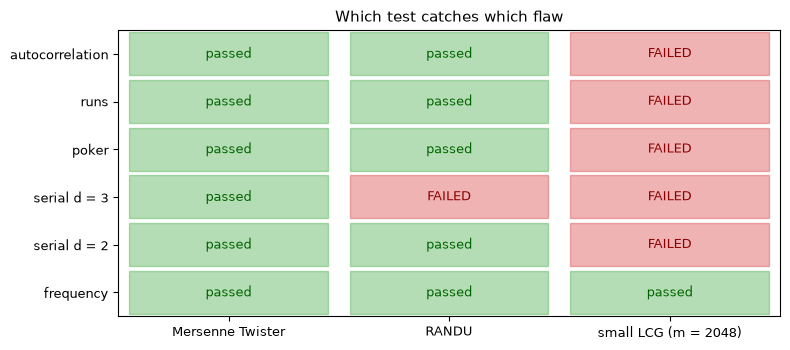

In [8]:
def all_tests(xs):
    out = {}
    out["frequency"] = frequency_test(xs)[1]
    out["serial d = 2"] = serial_test(xs, d=2, k=12)[1]
    out["serial d = 3"] = serial_test(xs, d=3, k=8)[1]
    out["poker"] = poker_test(xs)[0][1]
    out["runs"] = runs_test(xs)[3]
    out["autocorrelation"] = autocorrelation(xs, 1)[2]
    return out


results = {name: all_tests(SAMPLES[name]) for name, _ in GENERATORS}
test_names = list(results["Mersenne Twister"])

print(f"{'test':16s}" + "".join(f"{n[:18]:>20s}" for n, _ in GENERATORS))
for t in test_names:
    row = ""
    for name, _ in GENERATORS:
        p = results[name][t]
        row += f"{('p = ' + format(p, '.4f')) if p >= 1e-4 else 'p < 0.0001':>20s}"
    print(f"{t:16s}{row}")

fig, ax = plt.subplots(figsize=(8, 3.6))
for j, (name, _) in enumerate(GENERATORS):
    for i, t in enumerate(test_names):
        p = results[name][t]
        ok = p > 0.01
        ax.add_patch(plt.Rectangle((j - 0.45, i - 0.45), 0.9, 0.9,
                                   color="tab:green" if ok else "tab:red", alpha=0.35))
        ax.text(j, i, "passed" if ok else "FAILED", ha="center", va="center",
                fontsize=9, color="darkgreen" if ok else "darkred")
ax.set_xticks(range(len(GENERATORS)))
ax.set_xticklabels([n for n, _ in GENERATORS], fontsize=9)
ax.set_yticks(range(len(test_names)))
ax.set_yticklabels(test_names, fontsize=9)
ax.set_xlim(-0.5, len(GENERATORS) - 0.5)
ax.set_ylim(-0.5, len(test_names) - 0.5)
ax.set_title("Which test catches which flaw", fontsize=11)
plt.tight_layout()
plt.show()

The table sums up the whole point:

- **The small LCG** fails almost everywhere — a flaw like that will be found by anyone.
- **RANDU** passes the frequency test, the poker test and the two-dimensional serial test. It only
  falls on the **three-dimensional** serial test. Anyone who tested up to two dimensions found
  nothing.
- **The Mersenne Twister** passes everything we threw at it. Which does not mean it has no flaw — it
  means these tests do not see it. (MT19937 really does fail some of the tests in the TestU01 battery,
  they are just finer than ours.)

## 9. A second-order test

One test on one sequence gives one number, and that can come out suspicious even for a perfect
generator — in one case out of a hundred at a threshold of $0.01$. Testing properly means running the
test on many independent stretches and looking at the **distribution of the p-values**. Under $H_0$
they should be uniform on $[0,1)$.

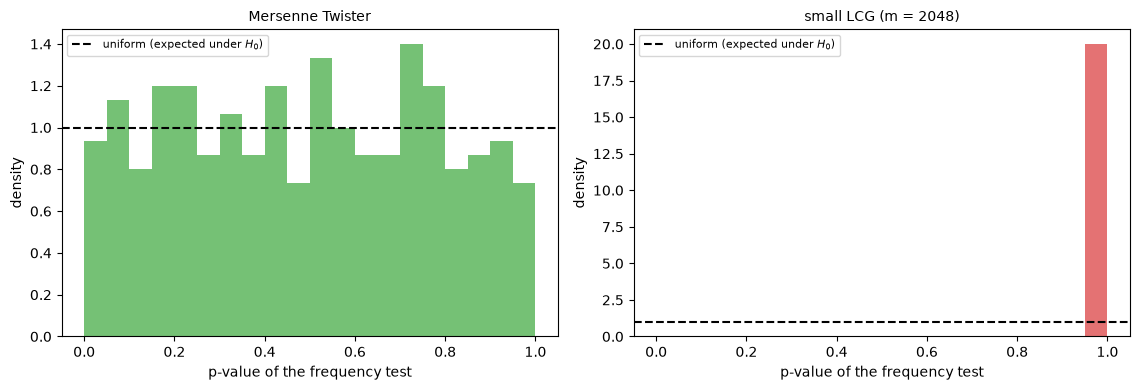

For a good generator the histogram of p-values is flat.
For a bad one it piles up at zero — the test rejects it almost every time.


In [9]:
def p_values(gen_f, blocks=300, length=2000, k=20):
    out = []
    for _ in range(blocks):
        out.append(frequency_test(gen_f(length), k=k)[1])
    return out


fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, (name, f) in zip(axes, (("Mersenne Twister", mt), ("small LCG (m = 2048)", lcg_small))):
    ps = p_values(f)
    ax.hist(ps, bins=20, range=(0, 1), density=True, alpha=0.65,
            color="tab:green" if "Twister" in name else "tab:red")
    ax.axhline(1.0, color="k", ls="--", label="uniform (expected under $H_0$)")
    ax.set_xlabel("p-value of the frequency test")
    ax.set_ylabel("density")
    ax.set_title(name, fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("For a good generator the histogram of p-values is flat.")
print("For a bad one it piles up at zero — the test rejects it almost every time.")

## Summary

| Test | What it measures | What it catches |
|------|------------------|-----------------|
| frequency | the uniformity of the values | gross non-uniformity, a small modulus |
| serial, $d = 2$ | the independence of pairs | a lattice visible in the plane |
| serial, $d = 3$ | the independence of triples | **RANDU** and its 15 planes |
| poker | repetition within a quintuple | a narrowed range of values |
| runs | the order, not the values | a trend, a periodicity |
| autocorrelation | linear dependence at lag $\ell$ | short-term memory |
| second-order | the distribution of the p-values | systematic deviations a single run does not show |

Three things to take away:

1. **χ² is the common form.** Sort into bins, compare with the expectation, compute a p-value.
2. **"It passed" only means "this test does not see this flaw."** RANDU passed everything except a
   single test — and that single one was enough.
3. **Test in more dimensions than you think you need.** A flaw hides in the dimension you are not
   testing, and comes out exactly when a simulation runs in it.

### Try it yourself

1. Run the three-dimensional serial test on RANDU with $k = 4$ instead of $8$. Does it pass? Why does
   a coarser division hide the flaw?
2. Add a four-dimensional serial test. How many samples do you need for every $E_i$ to be at least 5?
3. Write a gap test: track the lengths of the gaps between visits to the interval $(\alpha, \beta)$;
   they have a geometric distribution. Does it catch RANDU?
4. Take a generator that returns `(i % 1000) / 1000` for increasing `i`. Which of our tests exposes it
   first?
5. Run the second-order test on RANDU with the three-dimensional serial test and draw the histogram of
   p-values. What does an utter failure look like?